# Case Study 04 — Forecasting COVID-19 deaths

**Goal.** Given the daily global count of reported COVID-19 deaths, forecast
the coming weeks with several models and compare them honestly.

This notebook is the twin of Case Study 01 (climate) — the workflow is
identical, but the series is very different, and the differences are the
lesson:

- the data are **counts** (daily deaths), not temperatures;
- seasonality is **strong and weekly** (reporting cycles), period 7;
- the raw file is **cumulative** — and we will argue explicitly why we model
  the *daily* series instead.

Dataset: the Johns Hopkins CSSE time series
(`Data/time_series_covid19_deaths_global.csv`, snapshot frozen at
15 May 2022 — see `Data/README.md`).

## Part 1 — Load the data: cumulative vs daily

The file holds one row per country/region and one column per day, with
**cumulative** deaths. We aggregate the world by summing all rows per day:

(285, 849)
845 days: 22 Jan 2020 – 15 May 2022


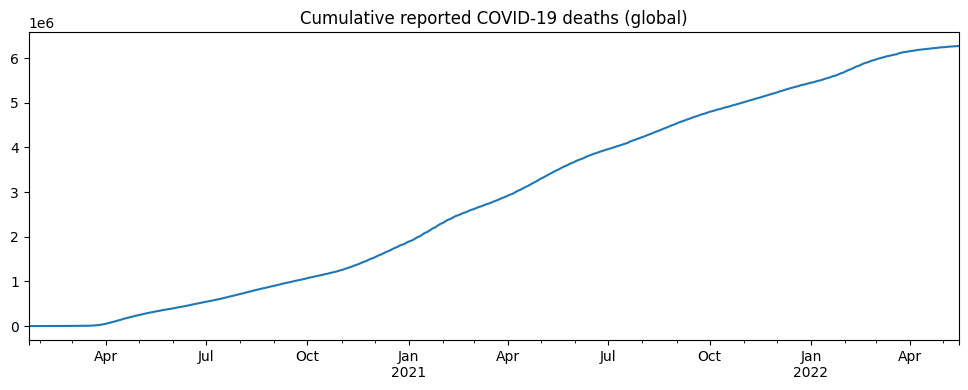

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

deaths_df = pd.read_csv('../../Data/time_series_covid19_deaths_global.csv')
print(deaths_df.shape)

date_cols = deaths_df.columns[4:]            # skip Province/Country/Lat/Long
cumulative = deaths_df[date_cols].sum()
cumulative.index = pd.to_datetime(cumulative.index, format='%m/%d/%y')
cumulative = cumulative.asfreq('D')
print(f'{len(cumulative)} days: {cumulative.index[0]:%d %b %Y} – '
      f'{cumulative.index[-1]:%d %b %Y}')

cumulative.plot(figsize=(12, 4),
                title='Cumulative reported COVID-19 deaths (global)')
plt.savefig('cummulative_daily_deaths.png', bbox_inches='tight')
plt.show()

**Why not model the cumulative curve directly?** Three reasons:

1. A cumulative sum is monotonically non-decreasing by construction — it is
   *maximally* non-stationary, the worst possible input for ARIMA-family
   models.
2. Its forecast errors are uninterpretable: the curve rockets up for most of
   the record, so even a useless model looks good in R².
3. The *question* "how bad is this week going to be?" is a question about
   **daily** counts, not about totals.

The daily series is the first difference of the cumulative one. A subtlety:
countries occasionally *revise* earlier counts, making a few daily values
**negative**. Those are bookkeeping artefacts, not events; we clip them to
zero and say so out loud:

0 negative daily values (data revisions) clipped to 0


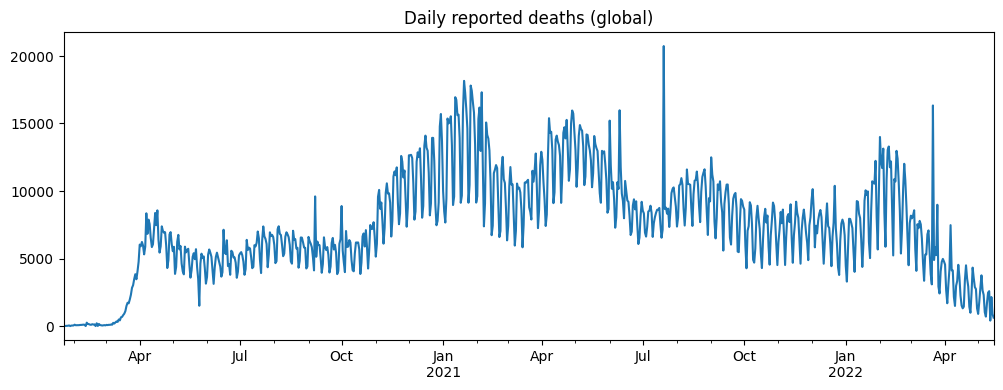

In [2]:
daily = cumulative.diff().dropna()
n_negative = (daily < 0).sum()
daily = daily.clip(lower=0)
print(f'{n_negative} negative daily values (data revisions) clipped to 0')

daily.plot(figsize=(12, 4), title='Daily reported deaths (global)')
plt.savefig('daily_deaths_diff.png', bbox_inches='tight')
plt.show()

## Part 2 — Look for structure

Two things jump out of the daily plot: several broad epidemic waves (a
slowly-varying mean, so the series is not stationary), and a tight, regular
"wiggle" on top. Zooming in on a few weeks makes its period obvious — count
the peaks: there are 7 per week. This is the **weekly reporting cycle**
(when offices close on weekends, registrations catch up mid-week), not
biology.

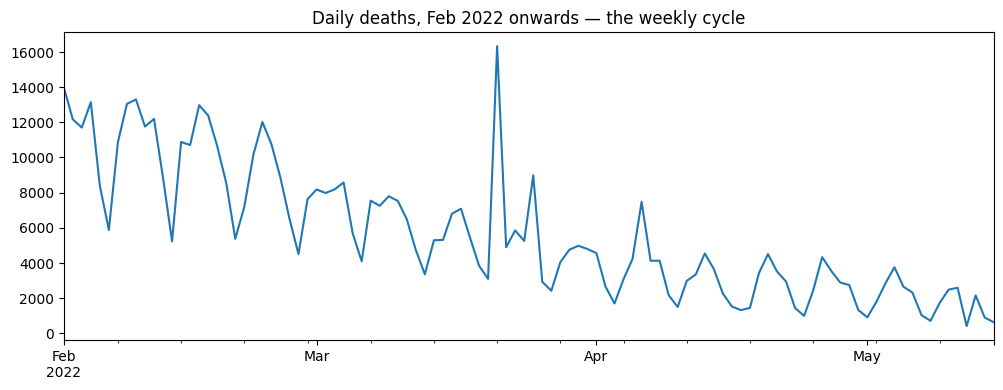

In [3]:
daily.loc['2022-02-01':].plot(figsize=(12, 4),
                              title='Daily deaths, Feb 2022 onwards — the weekly cycle')
plt.savefig('daily_deaths_diff_sample.png', bbox_inches='tight')
plt.show()

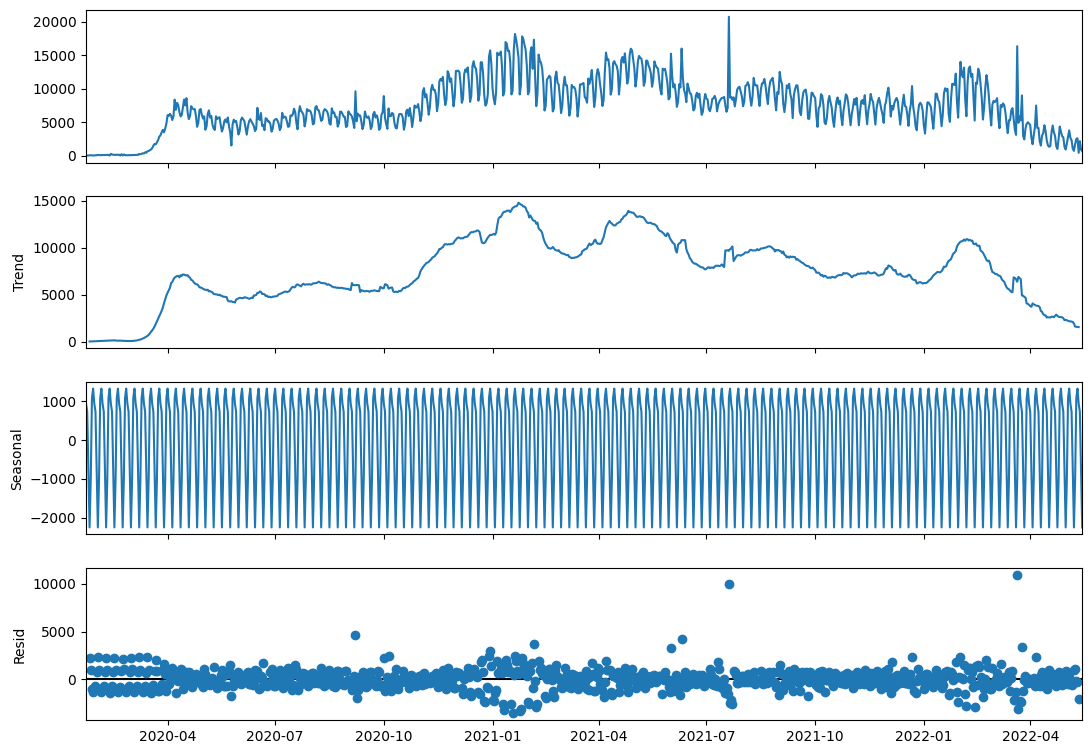

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomp = seasonal_decompose(daily, model='additive', period=7)
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.savefig('trends_seasons.png', bbox_inches='tight')
plt.show()

The decomposition confirms it: a strong 7-day seasonal component (roughly
±2,000 deaths) riding on the epidemic-wave trend. Any serious model of this
series must handle the weekly season — which is exactly what the **seasonal
orders** of SARIMAX are for.

## Part 3 — Stationarity

Recall the rule from Case Study 01: a small ADF p-value (< 0.05) lets us
reject "there is a unit root" – i.e. reject non-stationarity. Let's see where
the daily series stands, with and without differencing:

In [5]:
from statsmodels.tsa.stattools import adfuller

def adf_report(series, label):
    stat, p, *_ , crit = adfuller(series.dropna())
    print(f'{label:<24} p-value = {p:.4g}   '
          f'{"STATIONARY" if p < 0.05 else "not stationary"}')

adf_report(daily, 'daily deaths')
adf_report(daily.diff(), 'first difference')

daily deaths             p-value = 0.09103   not stationary
first difference         p-value = 0.0005151   STATIONARY


The raw daily series already sits close to (or past) the stationarity
threshold — the waves wander, but on these horizons it nearly passes. Rather
than decreeing `d` ourselves, we will let `auto_arima` choose it and pay the
AIC price if it is wrong. (Case Study 01 shows the manual-differencing
approach and the cumsum inverse if you need them.)

## Part 4 — Train/test split

We hold out the **last 30 days** — one month ahead being the operationally
interesting horizon here:

train: 23 Jan 2020 – 15 Apr 2022 (814 days)
test:  16 Apr 2022 – 15 May 2022 (30 days)


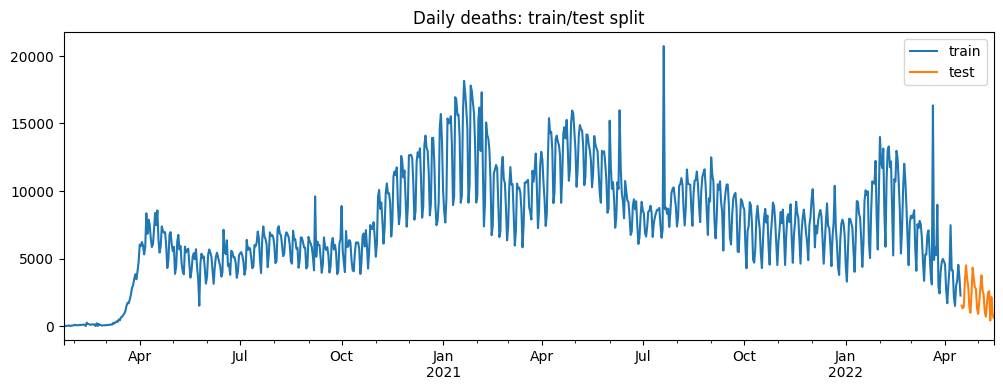

In [6]:
n_test = 30
train = daily.iloc[:-n_test]
test = daily.iloc[-n_test:]
print(f'train: {train.index[0]:%d %b %Y} – {train.index[-1]:%d %b %Y} ({len(train)} days)')
print(f'test:  {test.index[0]:%d %b %Y} – {test.index[-1]:%d %b %Y} ({len(test)} days)')

ax = train.plot(figsize=(12, 4), label='train', title='Daily deaths: train/test split')
test.plot(ax=ax, label='test')
ax.legend()
plt.savefig('training_set.png', bbox_inches='tight')
plt.show()

## Part 5 — SARIMAX and auto_arima

Same parameters as Case Study 01, now with period **7**:

- `(p, d, q)`: autoregression, differencing, moving-average for the
  non-seasonal part;
- `(P, D, Q, 7)`: the same at the weekly lag (e.g. `P=1` uses the value
  exactly one week ago).

We fit a hand-picked guess first, then a stepwise auto_arima search guided
by AIC:

The `initialization='approximate_diffuse'` argument in the fits below is
worth knowing: for seasonal models, statsmodels' default stationary
initialisation of the state vector can hit numerical trouble on some series
(an LU-decomposition error deep in the Kalman-filter setup). Approximate
diffuse initialisation sidesteps it with no cost to the fitted model.

In [7]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

manual = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),
                 initialization='approximate_diffuse')
manual_fit = manual.fit(disp=False)
print(manual_fit.summary().tables[1])

/home/abshe/.local/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/abshe/.local/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0743      0.032      2.314      0.021       0.011       0.137
ma.L1         -0.7475      0.028    -26.705      0.000      -0.802      -0.693
ar.S.L7        1.0000      0.007    150.020      0.000       0.987       1.013
ma.S.L7       -0.7535      0.019    -40.631      0.000      -0.790      -0.717
sigma2      1.284e+06   1.92e+04     67.001      0.000    1.25e+06    1.32e+06


In [8]:
import pmdarima as pm

auto = pm.auto_arima(train, seasonal=True, m=7, stepwise=True,
                     suppress_warnings=True, error_action='ignore', trace=True)
print(auto.summary())

Performing stepwise search to minimize aic


 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=inf, Time=6.16 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=14625.804, Time=0.03 sec


 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=14148.502, Time=0.93 sec


 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=14264.036, Time=1.51 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=14623.806, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[7] intercept   : AIC=14626.701, Time=0.04 sec


 ARIMA(1,1,0)(2,0,0)[7] intercept   : AIC=14028.997, Time=17.70 sec


...

 ARIMA(4,1,0)(1,0,1)[7] intercept   : AIC=13817.176, Time=10.92 sec


 ARIMA(3,1,1)(1,0,1)[7] intercept   : AIC=13932.308, Time=6.28 sec


 ARIMA(2,1,1)(1,0,1)[7] intercept   : AIC=13980.373, Time=7.08 sec


 ARIMA(4,1,1)(1,0,1)[7] intercept   : AIC=13915.221, Time=13.45 sec


 ARIMA(3,1,0)(1,0,1)[7]             : AIC=inf, Time=nan sec

Best model:  ARIMA(3,1,0)(1,0,1)[7] intercept
Total fit time: 583.624 seconds
                                      SARIMAX Results                                      
Dep. Variable:                                   y   No. Observations:                  814
Model:             SARIMAX(3, 1, 0)x(1, 0, [1], 7)   Log Likelihood               -6896.973
Date:                             Fri, 23 Oct 2026   AIC                          13807.946
Time:                                     14:43:53   BIC                          13840.851
Sample:                                 01-23-2020   HQIC                         13820.577
                                      - 04-15-2022                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------

auto_arima chose: (3, 1, 0) (1, 0, 1, 7)


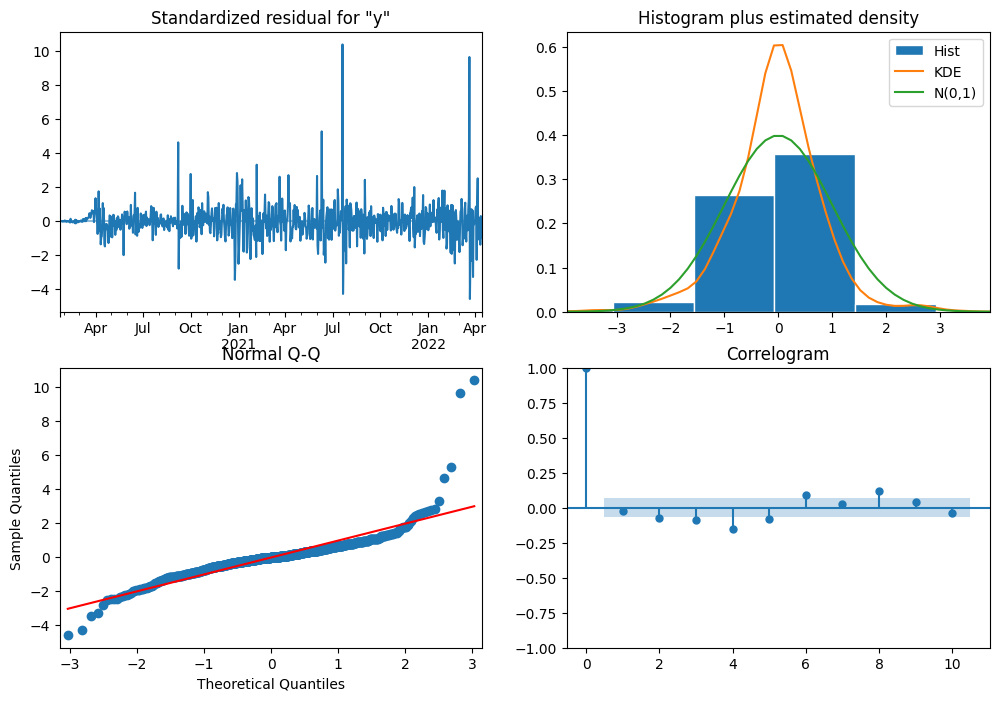

In [9]:
best_order, best_seasonal = auto.order, auto.seasonal_order
print('auto_arima chose:', best_order, best_seasonal)

auto_fit = SARIMAX(train, order=best_order, seasonal_order=best_seasonal,
                   initialization='approximate_diffuse').fit(disp=False)
auto_fit.plot_diagnostics(figsize=(12, 8))
plt.show()

Read the diagnostics as in Case Study 01: residuals should look like
structureless noise. Epidemic count data stretch the assumptions (fat right
tail, variance growing with the level — a Poisson-ish signature), so
moderate non-normality in the histogram/Q–Q panels is expected; what we
really care about is an empty **correlogram**.

## Part 6 — Forecast the test month

`get_forecast` comes with prediction intervals — and we again insist on the
naive benchmark first: *next week repeats this week* (repeat the last 7
training days across the 30-day window).

In [10]:
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

# seasonal-naive baseline: the last training week, repeated
naive_test = np.resize(train.iloc[-7:].values, len(test))

metrics = {}
def record(name, actual, predicted):
    metrics[name] = {'MAE': mean_absolute_error(actual, predicted),
                     'RMSE': rmse(actual, predicted)}
record('seasonal naive', test, naive_test)

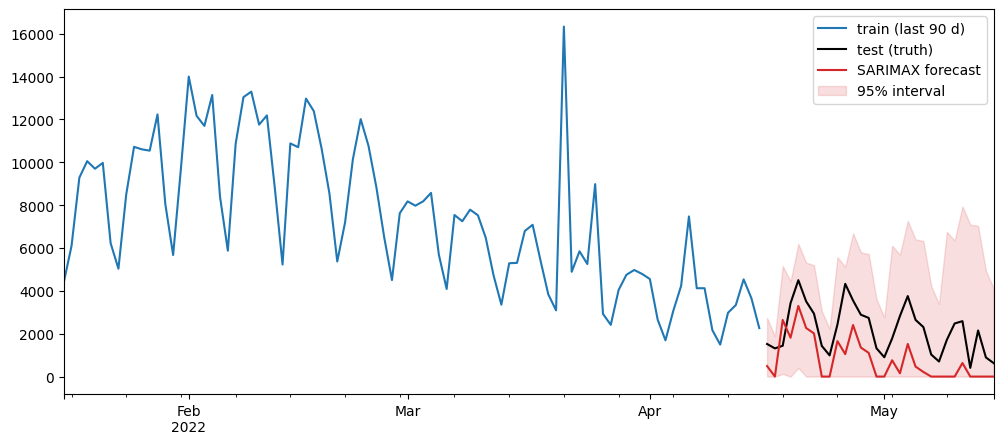

In [11]:
forecast = auto_fit.get_forecast(steps=len(test))
pred_sarimax = forecast.predicted_mean.clip(lower=0)   # counts cannot be negative
ci = forecast.conf_int()
record('SARIMAX (auto)', test, pred_sarimax)

fig, ax = plt.subplots(figsize=(12, 5))
train.iloc[-90:].plot(ax=ax, label='train (last 90 d)')
test.plot(ax=ax, color='k', label='test (truth)')
pred_sarimax.plot(ax=ax, color='tab:red', label='SARIMAX forecast')
ax.fill_between(ci.index, np.clip(ci.iloc[:, 0], 0, None), ci.iloc[:, 1],
                color='tab:red', alpha=0.15, label='95% interval')
ax.legend()
plt.savefig('SARIMAX_prediction.png', bbox_inches='tight')
plt.show()

The `clip(lower=0)` trick deserves a word: the model knows nothing about
count constraints and *will* predict negative deaths when the level falls —
a reminder that model outputs are suggestions to be checked, not truths.

## Part 7 — ML models on calendar features

Same trick as Case Study 01: turn the calendar into features. Here the
relevant cycle is the **week**, so we encode the day of week on a circle,
plus a simple time counter for the trend:

In [12]:
def make_calendar_features(index):
    dow = index.dayofweek.values   # 0 = Monday ... 6 = Sunday
    return pd.DataFrame({
        't': np.arange(len(index)) + 1,
        'dow_sin': np.sin(2 * np.pi * dow / 7),
        'dow_cos': np.cos(2 * np.pi * dow / 7),
    }, index=index)

X_train = make_calendar_features(train.index)
X_test = make_calendar_features(test.index)
# the time counter must measure distance from the SAME origin for both:
X_test['t'] = X_train['t'].iloc[-1] + np.arange(1, len(test) + 1)

In [13]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                   random_state=0, n_jobs=-1)
xgb.fit(X_train, train, verbose=False)
pred_xgb = np.clip(xgb.predict(X_test), 0, None)
record('XGBoost', test, pred_xgb)

In [14]:
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(0)

scaler = StandardScaler().fit(X_train)          # TRAIN statistics only
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

nn = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(3,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1),
])
nn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mae')
nn.fit(Xs_train, train.values, epochs=60, batch_size=32, verbose=0)

pred_nn = np.clip(nn.predict(Xs_test, verbose=0).ravel(), 0, None)
record('neural network', test, pred_nn)

I0000 00:00:1792727269.913184 2067474 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792727269.970483 2067474 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792727272.892976 2067474 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Part 8 — Compare, and bring the units back to life

Daily-scale MAE/RMSE are abstract. For an epidemic, the question a reader
actually cares about is usually: **how many deaths in total over the period?**
That is the cumulative scale — and we can evaluate on it. Since each model
predicts the daily increments, its implied cumulative total over the test
window is just the sum of its daily predictions. We compare each model's
cumulative test total against the true one, as a percentage error. (This is
the same cumsum-inverse idea from Case Study 01: the daily and cumulative
scales are two views of one series.)

In [15]:
results = pd.DataFrame(metrics).T.sort_values('RMSE')
print('=== errors on the DAILY scale (held-out 30 days) ===')
print(results.to_string(float_format=lambda v: f'{v:.1f}'))

true_total = test.sum()
print(f'\n=== implied TOTAL deaths over the window (truth: {true_total:,.0f}) ===')
for name, pred in [('seasonal naive', naive_test), ('SARIMAX (auto)', pred_sarimax),
                   ('XGBoost', pred_xgb), ('neural network', pred_nn)]:
    err = 100 * (np.sum(pred) - true_total) / true_total
    print(f'  {name:<18s} {np.sum(pred):>12,.0f}  ({err:+.1f} %)')

best_name = results['RMSE'].idxmin()
print(f'\nBest model on the test window (RMSE): {best_name}')

=== errors on the DAILY scale (held-out 30 days) ===
                  MAE   RMSE
XGBoost         678.8  948.5
seasonal naive  825.8 1040.8
SARIMAX (auto) 1455.9 1598.6
neural network 7404.7 7459.6

=== implied TOTAL deaths over the window (truth: 65,107) ===
  seasonal naive           85,327  (+31.1 %)
  SARIMAX (auto)           23,839  (-63.4 %)
  XGBoost                  78,808  (+21.0 %)
  neural network          287,249  (+341.2 %)

Best model on the test window (RMSE): XGBoost


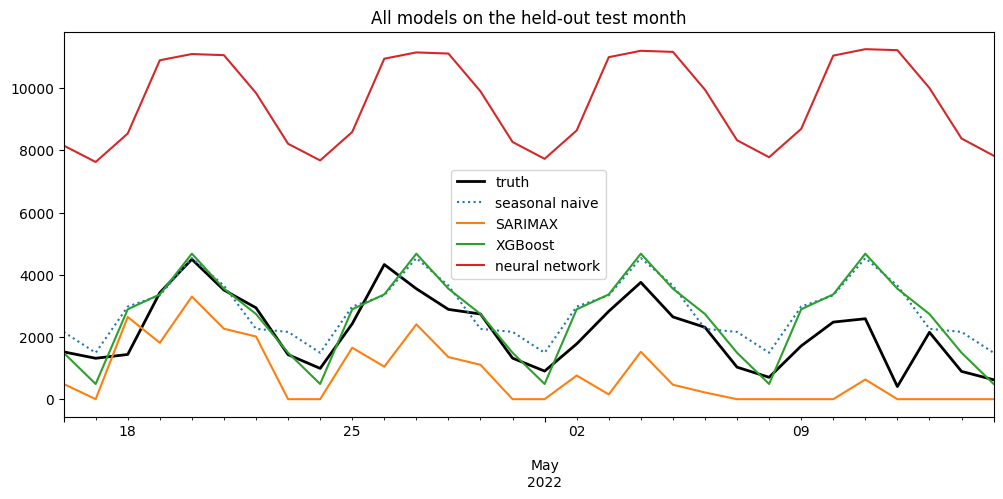

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
test.plot(ax=ax, color='k', lw=2, label='truth')
ax.plot(test.index, naive_test, ':', label='seasonal naive')
ax.plot(test.index, pred_sarimax.values, label='SARIMAX')
ax.plot(test.index, pred_xgb, label='XGBoost')
ax.plot(test.index, pred_nn, label='neural network')
ax.set_title('All models on the held-out test month')
ax.legend()
plt.savefig('comparison_forecasts.png', bbox_inches='tight')
plt.show()

### Interrogating the scoreboard

This test window (mid-April → mid-May 2022) sits in a steep post-Omicron
decline, and the table is a catalogue of the **four ways forecasting models
fail**:

- **Seasonal naive** repeats the last observed week; with deaths falling
  fast, it overshoots the total by ~30 %.
- **SARIMAX (auto)** fitted a strongly negative short-term drift to the steep
  decline and, integrating it, plunged toward (and past) zero — an undershoot
  of more than half the true total.
- **XGBoost** only knows the calendar: with its `t` trend frozen at the
  training edge (see Case Study 01's extrapolation warning) it keeps the
  weekly shape near the right level and takes the window — a *least-wrong*
  kind of win.
- **Neural network** extrapolated its `t` trend catastrophically: ReLU
  slopes, unconstrained beyond the training range, ran away to absurd death
  counts. Now compare against Case Study 01, where the *same* linear
  extrapolation over the same architecture and feature set **won** the
  comparison.

The lesson compounds the one from the climate study: model and feature
choices interact with the *specific series*. No model here was reliably
right across both case studies — the reliable thing was the **protocol**:
held-out window, naive baseline, and conclusions computed from the numbers.
When models disagree this wildly, the honest output is the disagreement,
with uncertainty intervals — which is what the final part produces.

## Part 9 — Forecast the next fortnight

Refit on *all* data, forecast 14 days past the record, with intervals:

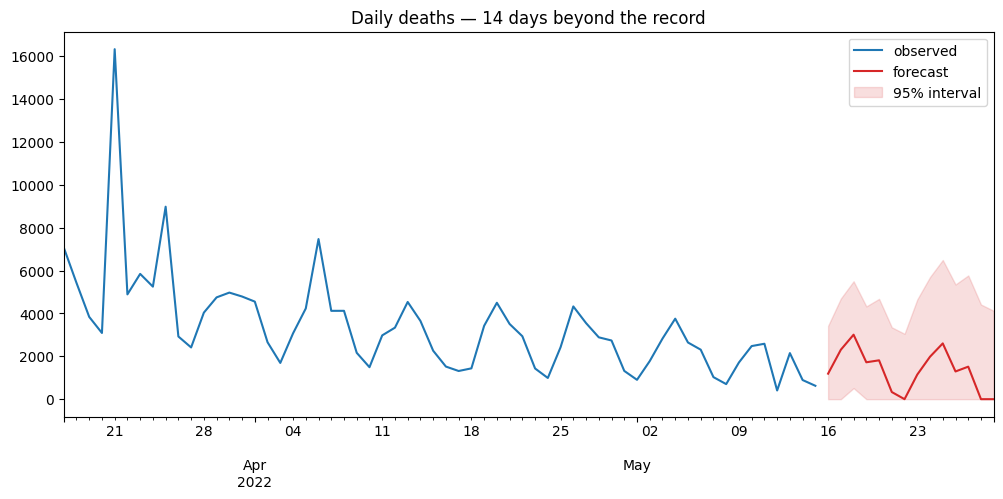

2022-05-16    1190
2022-05-17    2307
2022-05-18    3009
2022-05-19    1721
2022-05-20    1813
2022-05-21     333
2022-05-22       0
2022-05-23    1148
2022-05-24    1982
2022-05-25    2603
2022-05-26    1293
2022-05-27    1517
2022-05-28       0
2022-05-29       0
Freq: D


In [17]:
final_fit = SARIMAX(daily, order=best_order, seasonal_order=best_seasonal,
                    initialization='approximate_diffuse').fit(disp=False)
future = final_fit.get_forecast(steps=14)
fut_mean = future.predicted_mean.clip(lower=0)
fut_ci = future.conf_int()

fig, ax = plt.subplots(figsize=(12, 5))
daily.iloc[-60:].plot(ax=ax, label='observed')
fut_mean.plot(ax=ax, color='tab:red', label='forecast')
ax.fill_between(fut_ci.index, np.clip(fut_ci.iloc[:, 0], 0, None), fut_ci.iloc[:, 1],
                color='tab:red', alpha=0.15, label='95% interval')
ax.set_title('Daily deaths — 14 days beyond the record')
ax.legend()
plt.show()

print(fut_mean.round(0).astype(int).to_string())

## Notes — where to go from here

You have the full classical forecasting workflow on a genuinely hard,
real-world series. Honest limitations and next steps:

- **Calendar features only go so far.** Our ML models see *time*, not the
  series. A stronger ML formulation uses **lagged values** as features
  (`deaths(t−1)`, `deaths(t−7)`, rolling means); beware, though, that
  multi-step forecasting then needs recursion or direct-horizon models.
- **Counts deserve count models.** Death counts are non-negative, discrete,
  and have variance growing with the mean — Poisson/negative-binomial
  regression or state-space count models handle this properly.
- **The weekly season is reporting, not biology.** Production pipelines
  often adjust reporting artefacts explicitly before modelling.
- **The prophet package** (which an earlier version of this notebook
  advertised but never used) automates trend-piecewise + multiple-seasonality
  fits — a reasonable next tool to try, not a replacement for the hygiene
  you've practised here: clean differencing, a held-out window, a naive
  baseline, and conclusions written from the numbers.